In [1]:
# Llama-3.2 is gated. Store a Kaggle secret named HF_TOKEN.
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login

try:
    token = UserSecretsClient().get_secret('HF_TOKEN')
    login(token=token)
    print('Hugging Face login: OK')
except Exception as exc:
    print('HF login was not completed automatically:', exc)
    print('If the model is already cached and accessible, you can continue.')


Hugging Face login: OK


In [2]:
import torch
from transformers import AutoModelForCausalLM
import matplotlib.pyplot as plt

model = AutoModelForCausalLM.from_pretrained('meta-llama/Llama-3.2-1B',)

config.json:   0%|          | 0.00/843 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.47GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/185 [00:00<?, ?B/s]

In [3]:
# TODO for Question 4
import numpy as np

LAYERS = [0, 7, 15]
TOP_K = 200
THRESHOLD = 50.0

results = {}
for k in LAYERS:
    q_weight = model.model.layers[k].self_attn.q_proj.weight.detach()
    U, S, Vh = torch.linalg.svd(q_weight.float(), full_matrices=False)
    energy_ratios = torch.cumsum(S ** 2, dim=0) / torch.sum(S ** 2) * 100

    min_rank = int((energy_ratios >= THRESHOLD).nonzero()[0].item()) + 1

    results[k] = {
        'S': S.cpu().numpy(),
        'energy': energy_ratios.cpu().numpy(),
        'min_rank': min_rank,
    }
    print(f'Layer {k:2d} | shape={tuple(q_weight.shape)} | '
          f'min rank (>=50% energy): {min_rank} | '
          f'energy@16: {energy_ratios[15].item():.2f}% | '
          f'energy@{TOP_K}: {energy_ratios[TOP_K-1].item():.2f}% | '
          f'S_max={S[0].item():.3f}, S_{TOP_K}={S[TOP_K-1].item():.3f}')

"""

Hint:
# Analyze the weights of the query projection layer (q_proj) where layer = k
 q_weight = model.model.layers[k].self_attn.q_proj.weight.detach()

# Apply SVD to decompose the weight matrix into U (left singular vectors), S (singular values), and V (right singular vectors).
 U, S, Vh = torch.linalg.svd(q_weight.float(), full_matrices=False)

# Compute the retained energy ratio (Cumulative energy) of each singular value.
energy_ratios = torch.cumsum(S ** 2, dim=0) / torch.sum(S ** 2) * 100
"""


Layer  0 | shape=(2048, 2048) | min rank (>=50% energy): 62 | energy@16: 34.77% | energy@200: 71.24% | S_max=31.358, S_200=2.426
Layer  7 | shape=(2048, 2048) | min rank (>=50% energy): 120 | energy@16: 15.39% | energy@200: 63.54% | S_max=10.337, S_200=1.976
Layer 15 | shape=(2048, 2048) | min rank (>=50% energy): 84 | energy@16: 20.95% | energy@200: 68.84% | S_max=12.881, S_200=1.704


'\n\nHint:\n# Analyze the weights of the query projection layer (q_proj) where layer = k\n q_weight = model.model.layers[k].self_attn.q_proj.weight.detach()\n\n# Apply SVD to decompose the weight matrix into U (left singular vectors), S (singular values), and V (right singular vectors).\n U, S, Vh = torch.linalg.svd(q_weight.float(), full_matrices=False)\n\n# Compute the retained energy ratio (Cumulative energy) of each singular value.\nenergy_ratios = torch.cumsum(S ** 2, dim=0) / torch.sum(S ** 2) * 100\n'

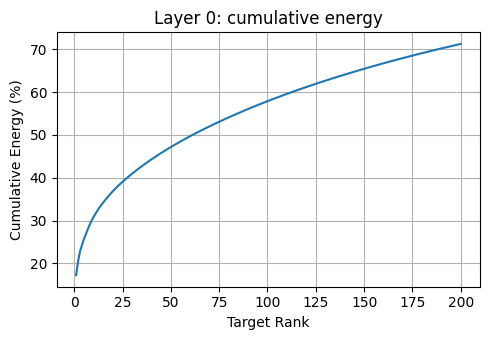

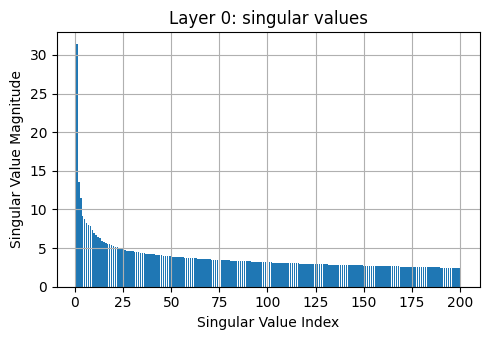

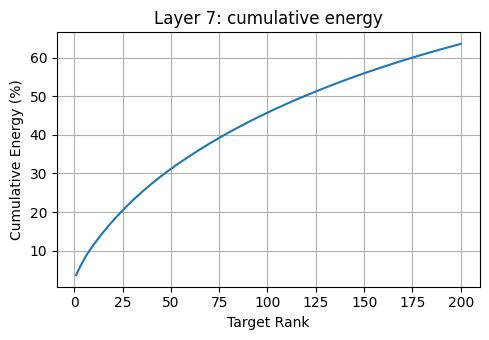

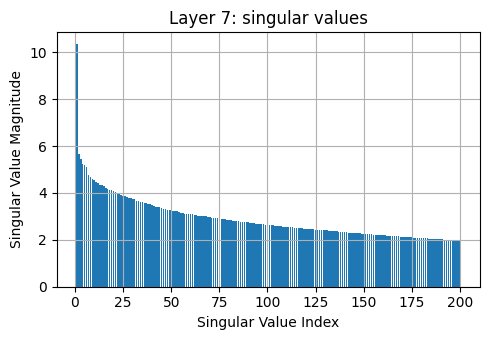

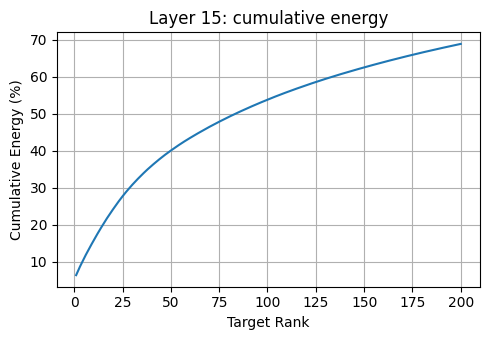

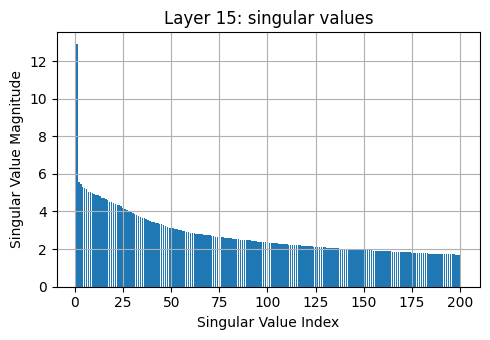

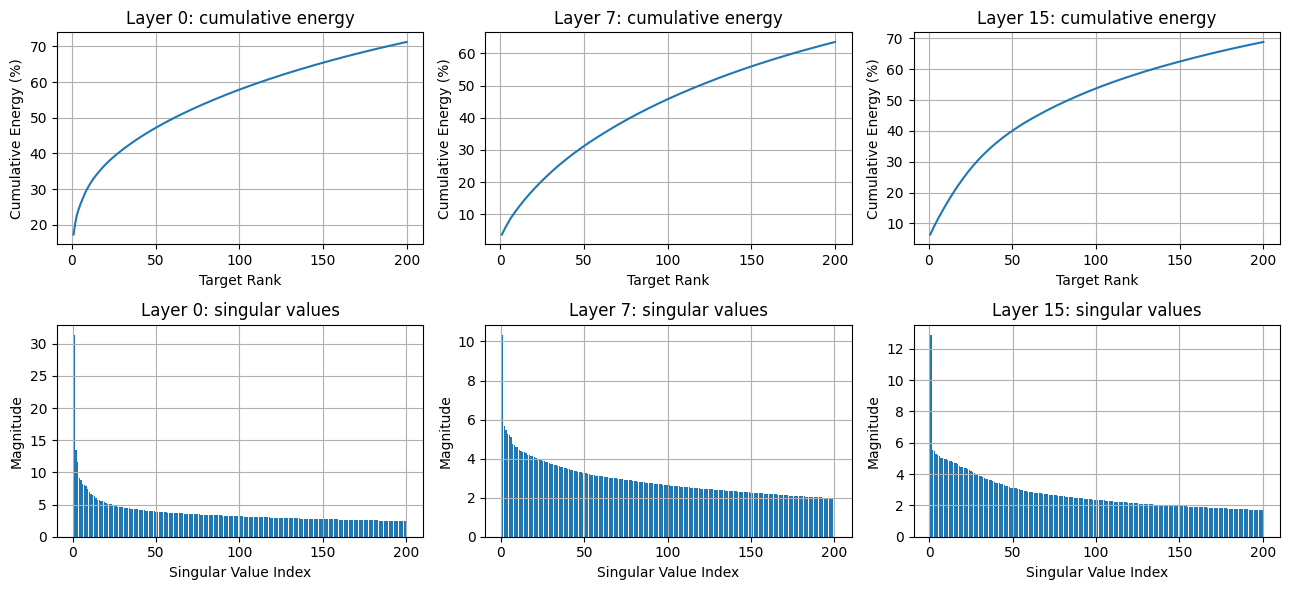

In [4]:
for k in LAYERS:
    S = results[k]['S'][:TOP_K]
    E = results[k]['energy'][:TOP_K]
    x = np.arange(1, TOP_K + 1)

    plt.figure(figsize=(5, 3.5))
    plt.plot(x, E)
    plt.xlabel('Target Rank'); plt.ylabel('Cumulative Energy (%)')
    plt.title(f'Layer {k}: cumulative energy'); plt.grid(True)
    plt.tight_layout(); plt.savefig(f'q4_layer{k}_energy.png', dpi=200); plt.show()

    plt.figure(figsize=(5, 3.5))
    plt.bar(x, S)
    plt.xlabel('Singular Value Index'); plt.ylabel('Singular Value Magnitude')
    plt.title(f'Layer {k}: singular values'); plt.grid(True)
    plt.tight_layout(); plt.savefig(f'q4_layer{k}_sv.png', dpi=200); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for col, k in enumerate(LAYERS):
    S = results[k]['S'][:TOP_K]; E = results[k]['energy'][:TOP_K]
    x = np.arange(1, TOP_K + 1)
    axes[0, col].plot(x, E); axes[0, col].grid(True)
    axes[0, col].set_title(f'Layer {k}: cumulative energy')
    axes[0, col].set_xlabel('Target Rank'); axes[0, col].set_ylabel('Cumulative Energy (%)')
    axes[1, col].bar(x, S); axes[1, col].grid(True)
    axes[1, col].set_title(f'Layer {k}: singular values')
    axes[1, col].set_xlabel('Singular Value Index'); axes[1, col].set_ylabel('Magnitude')
plt.tight_layout(); plt.savefig('q4_all_layers.png', dpi=200); plt.show()